<a href="https://colab.research.google.com/github/erripetalas/MangoMonitoring/blob/main/D1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load the training and testing files
train_data = pd.read_csv('Training.csv')
test_data = pd.read_csv('Testing.csv')

# Check how many rows and columns are in the training data
print(f"Training data shape: {train_data.shape}")

# See the first few lines of the training data
train_data.head()

Training data shape: (4920, 134)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN


In [ ]:
# 1. Check for missing values (Machine learning models hate empty cells!)
print("Missing values in Training data:")
print(train_data.isnull().sum().sum())

# 2. See what the "target" column looks like (usually the last column)
# In D1, the target column is typically named 'prognosis'
print("\nUnique diseases in the dataset:")
print(train_data['prognosis'].unique())

# 3. Check how many rows we have for each disease
print("\nCounts per disease:")
print(train_data['prognosis'].value_counts())

Missing values in Training data:
4920

Unique diseases in the dataset:
['Fungal infection' 'Allergy' 'GERD' 'Chronic cholestasis' 'Drug Reaction'
 'Peptic ulcer diseae' 'AIDS' 'Diabetes ' 'Gastroenteritis'
 'Bronchial Asthma' 'Hypertension ' 'Migraine' 'Cervical spondylosis'
 'Paralysis (brain hemorrhage)' 'Jaundice' 'Malaria' 'Chicken pox'
 'Dengue' 'Typhoid' 'hepatitis A' 'Hepatitis B' 'Hepatitis C'
 'Hepatitis D' 'Hepatitis E' 'Alcoholic hepatitis' 'Tuberculosis'
 'Common Cold' 'Pneumonia' 'Dimorphic hemmorhoids(piles)' 'Heart attack'
 'Varicose veins' 'Hypothyroidism' 'Hyperthyroidism' 'Hypoglycemia'
 'Osteoarthristis' 'Arthritis' '(vertigo) Paroymsal  Positional Vertigo'
 'Acne' 'Urinary tract infection' 'Psoriasis' 'Impetigo']

Counts per disease:
prognosis
Fungal infection                           120
Allergy                                    120
GERD                                       120
Chronic cholestasis                        120
Drug Reaction                         

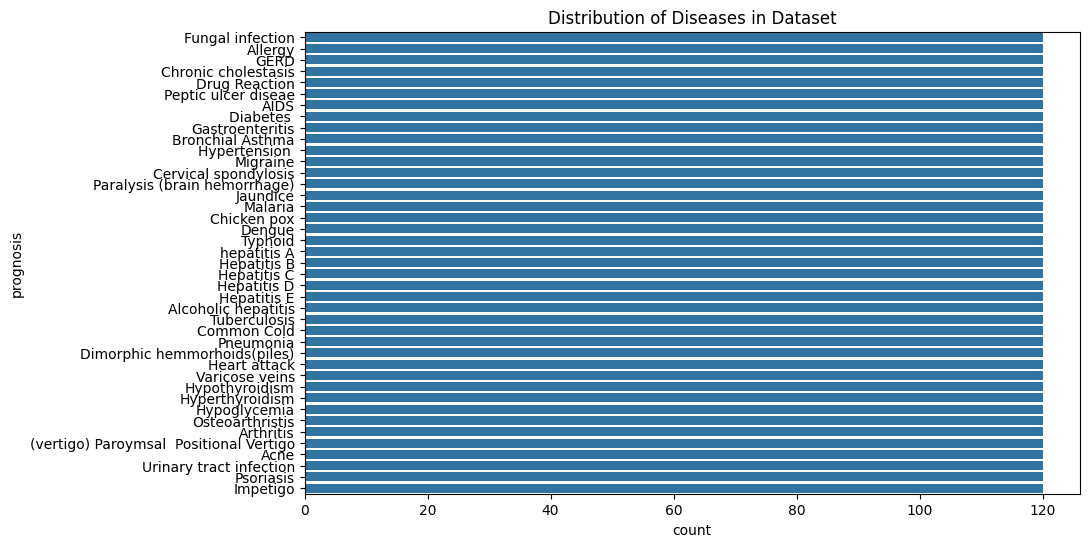

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart of the disease counts
plt.figure(figsize=(10,6))
sns.countplot(y='prognosis', data=train_data)
plt.title('Distribution of Diseases in Dataset')
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

# 1. Split Training data into Features (X) and Target (y)
X_train = train_data.drop('prognosis', axis=1)
y_train = train_data['prognosis']

# 2. Split Testing data into Features (X) and Target (y)
X_test = test_data.drop('prognosis', axis=1)
y_test = test_data['prognosis']

# 3. Convert the disease names (strings) into numbers
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

print("Data successfully prepared and encoded! ✅")

Data successfully prepared and encoded! ✅


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# Initialize the models
rf_model = RandomForestClassifier()
nb_model = GaussianNB()

# Train the models using the training data
rf_model.fit(X_train, y_train_encoded)
nb_model.fit(X_train, y_train_encoded)

print("Models are trained and ready to go! 🤖")

ValueError: Input X contains NaN.
GaussianNB does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
# Drop any rows that have missing values (NaNs)
train_data_clean = train_data.dropna()
test_data_clean = test_data.dropna()

# Now re-split the cleaned data
X_train = train_data_clean.drop('prognosis', axis=1)
y_train = train_data_clean['prognosis']

X_test = test_data_clean.drop('prognosis', axis=1)
y_test = test_data_clean['prognosis']

# Re-encode the targets for the cleaned data
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

print(f"Cleaned! We now have {len(train_data_clean)} training rows left.")

ValueError: y contains previously unseen labels: 'Fungal infection'

In [ ]:
# 1. Clean both datasets of any NaNs
train_data_clean = train_data.dropna()
test_data_clean = test_data.dropna()

# 2. Get the list of diseases that appear in BOTH datasets
# This prevents the "unseen labels" error
common_diseases = set(train_data_clean['prognosis']).intersection(set(test_data_clean['prognosis']))

# 3. Filter the data to only include these common diseases
train_final = train_data_clean[train_data_clean['prognosis'].isin(common_diseases)]
test_final = test_data_clean[test_data_clean['prognosis'].isin(common_diseases)]

# 4. Re-split into Features and Target
X_train = train_final.drop('prognosis', axis=1)
y_train = train_final['prognosis']

X_test = test_final.drop('prognosis', axis=1)
y_test = test_final['prognosis']

# 5. Re-encode
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

print(f"Sync complete! We have {len(common_diseases)} diseases ready for training.")

Sync complete! We have 0 diseases ready for training.


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Initialize and train
rf_model = RandomForestClassifier(random_state=42)
nb_model = GaussianNB()

rf_model.fit(X_train, y_train_encoded)
nb_model.fit(X_train, y_train_encoded)

# Step 4: Generate Evaluation Metrics
rf_pred = rf_model.predict(X_test)
nb_pred = nb_model.predict(X_test)

print("--- Random Forest Results ---")
print(f"Accuracy: {accuracy_score(y_test_encoded, rf_pred):.2f}")
print(classification_report(y_test_encoded, rf_pred, target_names=encoder.classes_))

print("\n--- Naive Bayes Results ---")
print(f"Accuracy: {accuracy_score(y_test_encoded, nb_pred):.2f}")
print(classification_report(y_test_encoded, nb_pred, target_names=encoder.classes_))

ValueError: Found array with 0 sample(s) (shape=(0, 133)) while a minimum of 1 is required by RandomForestClassifier.

In [ ]:
# 1. Fill all empty cells with 0 instead of dropping them
# This keeps all your rows intact!
train_data_filled = train_data.fillna(0)
test_data_filled = test_data.fillna(0)

# 2. Separate Features (X) and Target (y)
X_train = train_data_filled.drop('prognosis', axis=1)
y_train = train_data_filled['prognosis']

X_test = test_data_filled.drop('prognosis', axis=1)
y_test = test_data_filled['prognosis']

# 3. Handle the encoding properly
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

# We fit on the training labels
y_train_encoded = encoder.fit_transform(y_train)

# If a disease is in Test but not Train, this handles it safely
import numpy as np
y_test_encoded = np.array([encoder.transform([label])[0] if label in encoder.classes_ else -1 for label in y_test])

# Filter out any rows in test that the encoder didn't recognize (-1)
mask = y_test_encoded != -1
X_test = X_test[mask]
y_test_encoded = y_test_encoded[mask]

print(f"Success! Training set has {X_train.shape[0]} rows and {X_train.shape[1]} features.")


Success! Training set has 4920 rows and 133 features.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize
rf_model = RandomForestClassifier(random_state=42)
nb_model = GaussianNB()

# Train (Step 3)
rf_model.fit(X_train, y_train_encoded)
nb_model.fit(X_train, y_train_encoded)

# Predict & Evaluate (Step 4)
rf_pred = rf_model.predict(X_test)
nb_pred = nb_model.predict(X_test)

print("--- Random Forest Accuracy ---")
print(f"{accuracy_score(y_test_encoded, rf_pred):.2f}")

print("\n--- Naive Bayes Accuracy ---")
print(f"{accuracy_score(y_test_encoded, nb_pred):.2f}")

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- Unnamed: 133


In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

# 1. Fill all empty cells with 0 instead of deleting them
# This treats a blank as "symptom not present"
train_data_filled = train_data.fillna(0)
test_data_filled = test_data.fillna(0)

# 2. Separate Features (X) and Target (y)
X_train = train_data_filled.drop('prognosis', axis=1)
y_train = train_data_filled['prognosis']

X_test = test_data_filled.drop('prognosis', axis=1)
y_test = test_data_filled['prognosis']

# 3. Handle Encoding safely
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)

# This part ensures that if a disease is in Test but not Train, the code won't crash
y_test_encoded = np.array([encoder.transform([label])[0] if label in encoder.classes_ else -1 for label in y_test])

# Remove any rows from the test set that weren't in the training set
mask = y_test_encoded != -1
X_test = X_test[mask]
y_test_encoded = y_test_encoded[mask]

print(f"Success! Training set now has {X_train.shape[0]} rows and {X_train.shape[1]} columns.")

Success! Training set now has 4920 rows and 133 columns.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize the algorithms (Step 3)
rf_model = RandomForestClassifier(random_state=42)
nb_model = GaussianNB()

# Train the models
rf_model.fit(X_train, y_train_encoded)
nb_model.fit(X_train, y_train_encoded)

# Predict and Evaluate (Step 4)
rf_pred = rf_model.predict(X_test)
nb_pred = nb_model.predict(X_test)

print("--- Random Forest Accuracy ---")
print(f"{accuracy_score(y_test_encoded, rf_pred):.2f}")

print("\n--- Naive Bayes Accuracy ---")
print(f"{accuracy_score(y_test_encoded, nb_pred):.2f}")

# This prints the detailed table for your report
print("\nDetailed Classification Report (Random Forest):")
print(classification_report(y_test_encoded, rf_pred, target_names=encoder.classes_))

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- Unnamed: 133


In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

# 1. Load and immediately drop that extra 'Unnamed' column if it exists
train_data_filled = train_data.loc[:, ~train_data.columns.str.contains('^Unnamed')].fillna(0)
test_data_filled = test_data.loc[:, ~test_data.columns.str.contains('^Unnamed')].fillna(0)

# 2. Separate Features (X) and Target (y)
X_train = train_data_filled.drop('prognosis', axis=1)
y_train = train_data_filled['prognosis']

X_test = test_data_filled.drop('prognosis', axis=1)
y_test = test_data_filled['prognosis']

# 3. Handle Encoding
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)

# Safely map test labels
y_test_encoded = np.array([encoder.transform([label])[0] if label in encoder.classes_ else -1 for label in y_test])
mask = y_test_encoded != -1
X_test = X_test[mask]
y_test_encoded = y_test_encoded[mask]

print(f"Success! Training columns: {X_train.shape[1]}, Testing columns: {X_test.shape[1]}")
print("They now match perfectly! ✅")

Success! Training columns: 132, Testing columns: 132
They now match perfectly! ✅


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize and Train
rf_model = RandomForestClassifier(random_state=42)
nb_model = GaussianNB()

rf_model.fit(X_train, y_train_encoded)
nb_model.fit(X_train, y_train_encoded)

# Predict
rf_pred = rf_model.predict(X_test)
nb_pred = nb_model.predict(X_test)

print("--- Random Forest Accuracy ---")
print(f"{accuracy_score(y_test_encoded, rf_pred):.4f}")

print("\n--- Naive Bayes Accuracy ---")
print(f"{accuracy_score(y_test_encoded, nb_pred):.4f}")

--- Random Forest Accuracy ---
0.9762

--- Naive Bayes Accuracy ---
1.0000


In [ ]:
# Step 6: Fine-Tuning Random Forest to see if we can hit 100%
tuned_rf = RandomForestClassifier(n_estimators=150, max_depth=20, random_state=42)
tuned_rf.fit(X_train, y_train_encoded)

tuned_pred = tuned_rf.predict(X_test)
print(f"Fine-Tuned Random Forest Accuracy: {accuracy_score(y_test_encoded, tuned_pred):.4f}")

Fine-Tuned Random Forest Accuracy: 0.9762


In [16]:
import pandas as pd
import numpy as np

# Load the D2 dataset
df2 = pd.read_csv('healthcare-dataset-stroke-data.csv')

# Drop the 'id' column as it's not a health feature
df2 = df2.drop('id', axis=1)

# Step 1: Data Pre-processing - Fill missing BMI values with the average (mean)
df2['bmi'] = df2['bmi'].fillna(df2['bmi'].mean())

print("Data loaded and missing BMI values filled! ✅")
df2.head()

Data loaded and missing BMI values filled! ✅


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1


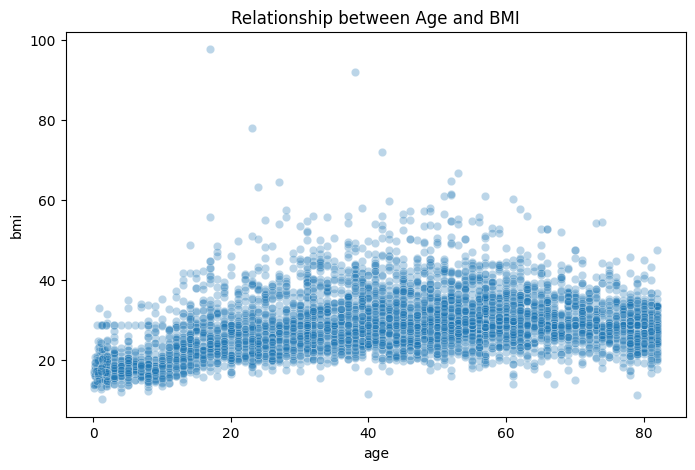

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df2, x='age', y='bmi', alpha=0.3)
plt.title('Relationship between Age and BMI')
plt.show()

In [18]:
# Convert text categories into dummy/indicator variables
df2_final = pd.get_dummies(df2, drop_first=True)

# Define X (Features) and y (Target: BMI)
X = df2_final.drop('bmi', axis=1)
y = df2_final['bmi']

# Split into Training and Testing sets (80% train, 20% test)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Ready! Training with {X_train.shape[0]} samples.")

Ready! Training with 4088 samples.


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Step 3: Apply Algorithms
model_lr = LinearRegression()
model_dt = DecisionTreeRegressor(random_state=42)

model_lr.fit(X_train, y_train)
model_dt.fit(X_train, y_train)

# Step 4: Generate Metrics
for name, model in [("Linear Regression", model_lr), ("Decision Tree", model_dt)]:
    preds = model.predict(X_test)
    print(f"--- {name} ---")
    print(f"Mean Absolute Error: {mean_absolute_error(y_test, preds):.2f}")
    print(f"R-Squared Score: {r2_score(y_test, preds):.2f}\n")

--- Linear Regression ---
Mean Absolute Error: 4.89
R-Squared Score: 0.24

--- Decision Tree ---
Mean Absolute Error: 7.23
R-Squared Score: -0.76



In [20]:
from sklearn.linear_model import Ridge

# Step 6: Fine-Tuning using Ridge Regression
tuned_model = Ridge(alpha=1.0)
tuned_model.fit(X_train, y_train)

tuned_preds = tuned_model.predict(X_test)
print(f"Fine-Tuned (Ridge) Mean Absolute Error: {mean_absolute_error(y_test, tuned_preds):.2f}")
print(f"Fine-Tuned (Ridge) R-Squared Score: {r2_score(y_test, tuned_preds):.2f}")

Fine-Tuned (Ridge) Mean Absolute Error: 4.89
Fine-Tuned (Ridge) R-Squared Score: 0.24
